In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### Start with the score and the raw differene

Score is fixed before the bedge appears; nobady manipulates it.

In [3]:
rng = np.random.default_rng(31)
score = rng.uniform(60, 100, 8000)
x = score - 80
badge = (x >= 0).astype(int)

Outcome is each seller's converstion rate in percentage points. 
We choose the true effect here so we can check our estimate later.

In [5]:
true_badge_effect = 2.5
conversion = 18 + 0.20*x + true_badge_effect*badge + rng.normal(0, 2.5, len(x))
sellers = pd.DataFrame({"score": score, "x": x, "badge": badge,
                        "conversion": conversion})

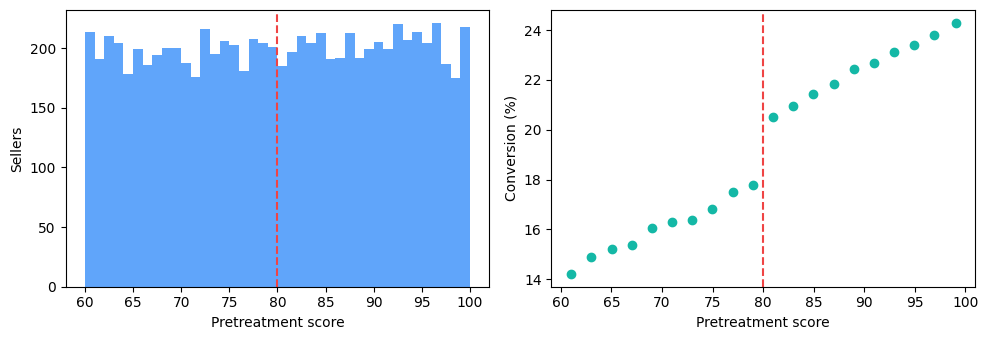

In [6]:
# Bin for a readable plot; estimation later uses individual sellers.
sellers["bin"] = pd.cut(sellers.score, np.arange(60, 102, 2))
binned = sellers.groupby("bin", observed=True)[["score", "conversion"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(score, bins=np.arange(60, 101, 1), color="#60a5fa")
ax[0].set(xlabel="Pretreatment score", ylabel="Sellers")
ax[1].scatter(binned.score, binned.conversion, color="#14b8a6")
ax[1].set(xlabel="Pretreatment score", ylabel="Conversion (%)")
for a in ax:
    a.axvline(80, color="#ef4444", linestyle="--")
fig.tight_layout()
means = sellers.groupby("badge").conversion.mean()

In [7]:
# Show the two group averages, their gap, and the effect we built into the data.
# The last row is a data-setup input, not an estimate from the comparison.
# Calculate the gap before rounding the displayed values.
pd.DataFrame({
    "Measure": ["Average conversion: without badge", "Average conversion: with badge",
                "Raw gap: with minus without", "True badge effect: data-setup input"],
    "Value": [means[0], means[1], means[1] - means[0], true_badge_effect],
    "Unit": ["%", "%", "percentage points", "percentage points"],
}).round(4)

,Measure,Value,Unit
0,Average conversion: without badge,16.0539,%
1,Average conversion: with badge,22.4575,%
2,Raw gap: with minus without,6.4036,percentage points
3,True badge effect: data-setup input,2.5000,percentage points


The table's “Raw gap” row subtracts average conversion without the badge from average conversion with it: about 6.40 percentage points. The 2.50-point “True badge effect” is different: we chose it in true_badge_effect = 2.5 when generating the data. We know it only because we set it in the data setup.

The raw comparison overstates that effect. Higher-scoring sellers would already convert better without the badge, so the 6.40-point gap includes that advantage. Next, we'll use RD to estimate the badge's effect near score 80.

The score histogram has no deliberate bunching at 80 because the data setup draws scores uniformly. That helps explain the design; it is not evidence that real sellers cannot manipulate a score. Next, narrow the comparison to the boundary.



#### Compare fitted outcomes at the cutoff

Now keep sellers within eight score points of 80. We subtract 80 from every score, so the cutoff becomes zero. This makes the badge coefficient easy to interpret.



Y=α+τD+βx+γ(D*x)+ε

Y is conversion, D equals 1 for a seller with the badge, and x is the seller's distance from the cutoff. At the cutoff, x equals zero. The score terms disappear, so τ is the difference between the two fitted conversion rates at score 80.

In [9]:
import statsmodels.formula.api as smf

                            OLS Regression Results                            
Dep. Variable:             conversion   R-squared:                       0.421
Model:                            OLS   Adj. R-squared:                  0.420
Method:                 Least Squares   F-statistic:                     780.3
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:52:36   Log-Likelihood:                -7478.9
No. Observations:                3219   AIC:                         1.497e+04
Df Residuals:                    3215   BIC:                         1.499e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     18.0562      0.123    146.740      0.0

,score,badge,conversion
2,86.909,1,22.608
3,78.902,0,19.815
4,87.097,1,17.603
9,72.086,0,15.535
10,83.611,1,18.016
14,76.976,0,11.618
17,72.089,0,12.392
21,80.704,1,18.481


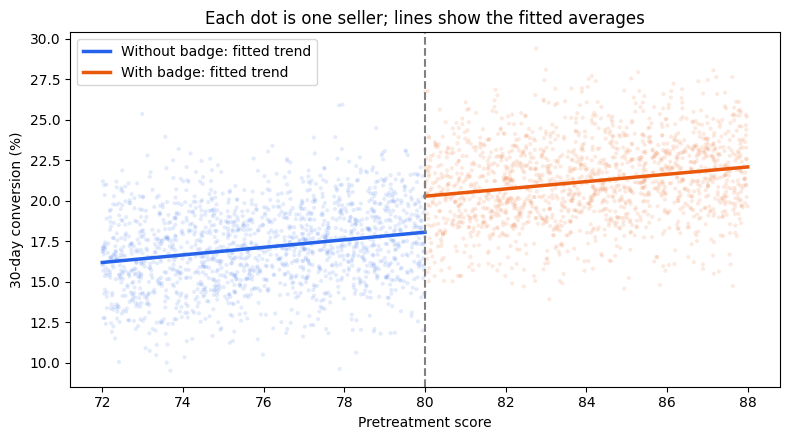

In [10]:
# Score is fixed before the badge appears; nobody manipulates it here.
rng = np.random.default_rng(31)
score = rng.uniform(60, 100, 8000)
x = score - 80
badge = (x >= 0).astype(int)
# Outcome is each seller's conversion rate in percentage points.
conversion = 18 + 0.20*x + 2.5*badge + rng.normal(0, 2.5, len(x))
sellers = pd.DataFrame({"score": score, "x": x, "badge": badge,
                        "conversion": conversion})
# Separate local slopes let conversion change with score on each side.
# The badge coefficient compares fitted outcomes AT score 80.
def fit_local(width):
    local = sellers[sellers.x.abs() <= width]
    return smf.ols("conversion ~ badge * x", data=local).fit(cov_type="HC3")

fit = fit_local(8)
local = sellers[sellers.x.abs() <= 8]

# Show every seller used in the fit. Transparency reveals dense regions.
# Fit each line up to the cutoff so the gap compares the SAME score, 80.
fig, ax = plt.subplots(figsize=(8, 4.5))
for group, label, color in [(0, "Without badge", "#2563eb"),
                             (1, "With badge", "#ea580c")]:
    observed = local[local.badge == group]
    ax.scatter(observed.score, observed.conversion, s=9, alpha=0.12,
               color=color, edgecolors="none", rasterized=True)
    distances = np.linspace(-8, 0, 100) if group == 0 else np.linspace(0, 8, 100)
    grid = pd.DataFrame({"x": distances, "badge": group})
    ax.plot(grid.x + 80, fit.predict(grid), color=color, linewidth=2.5,
            label=f"{label}: fitted trend")
ax.axvline(80, color="gray", linestyle="--")
ax.set(xlabel="Pretreatment score", ylabel="30-day conversion (%)",
       title="Each dot is one seller; lines show the fitted averages")
ax.legend()
fig.tight_layout()

# The full OLS summary includes every coefficient, HC3 standard errors,
# two-sided p-values, 95% confidence intervals, R-squared, and the model F-test.
# HC3 allows unequal residual variability; it does not correct RD smoothing bias.
print(fit.summary(alpha=0.05))  # 95% intervals; assess significance at 5%.

# A small raw-data preview connects the plotted dots to the underlying rows.
# badge = 1 means treated; conversion is in percent. This is not aggregated data.
local[["score", "badge", "conversion"]].head(8).round(3)

Among the 3,219 sellers close to the cutoff, conversion jumps by an estimated 2.223 percentage points at score 80. That is far smaller than the 6.40-point difference between all badged and unbadged sellers, and much closer to the effect set in the data setup of 2.50 points.

Who does this describe? The estimate applies to sellers near score 80 over the next 30 days. It is not an average effect for every Etsy seller or a forecast of total platform bookings.

Is the badge coefficient statistically significant? Yes, under this OLS model. Read the badge row: the estimate is 2.223, its standard error is 0.176, and its 95% confidence interval is 1.878 to 2.567 points. The two-sided p-value is below 0.001, so we reject a zero jump at the 5% level. A displayed 0.000 is rounding, not a probability of exactly zero or proof that the badge caused the lift.

What about the other coefficients? Intercept = 18.056 is predicted conversion at 80 without the badge. x = 0.234 is the conversion increase per score point below 80. badge:x = −0.008 changes the slope above 80; its p-value of 0.830 gives little evidence that the slopes differ. That does not prove they are identical, and we should not drop a design term just because its p-value is large.

How well does the whole model fit? R² = 0.421 means the model explains about 42% of conversion variation among these sellers. The overall F-statistic is 780.3, with p < 0.001: the badge and score terms jointly predict conversion. This is not the badge-effect test. The score could predict conversion even if the badge did nothing. Neither a high R² nor a small model p-value establishes causality.

What still needs checking? These intervals and tests use HC3, which allows the amount of unexplained variation to differ across sellers. It does not fix confounding, dependence between sellers, or bias from fitting a straight line near a cutoff. In this example the true trends are straight and sellers are independent. For a real rollout decision, we'd also use RD-specific, bias-corrected inference and finish the design checks. The statsmodels output reference explains the remaining summary fields.

#### Does the result hold when we change the comparison window?

,Window (+/- score points),Sellers,Jump (pp),HC3 SE (pp)
0,3,1205,2.181,0.295
1,5,2006,2.168,0.222
2,8,3219,2.223,0.176
3,12,4778,2.417,0.144


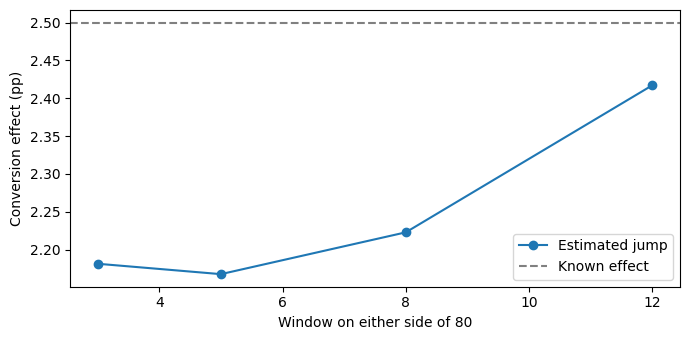

In [11]:
rng = np.random.default_rng(31)
score = rng.uniform(60, 100, 8000)
x = score - 80
badge = (x >= 0).astype(int)
# Outcome is each seller's conversion rate in percentage points.
conversion = 18 + 0.20*x + 2.5*badge + rng.normal(0, 2.5, len(x))
sellers = pd.DataFrame({"score": score, "x": x, "badge": badge,
                        "conversion": conversion})
# Separate local slopes let conversion change with score on each side.
# The badge coefficient compares fitted outcomes AT score 80.
def fit_local(width):
    local = sellers[sellers.x.abs() <= width]
    return smf.ols("conversion ~ badge * x", data=local).fit(cov_type="HC3")

# Set a range of windows in advance. Do not select by significance.
rows = []
for width in [3, 5, 8, 12]:
    fit = fit_local(width)
    rows.append({"Window (+/- score points)": width,
                 "Sellers": int(fit.nobs),
                 "Jump (pp)": fit.params["badge"],
                 "HC3 SE (pp)": fit.bse["badge"]})
results = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(results.iloc[:, 0], results["Jump (pp)"], "o-", label="Estimated jump")
ax.axhline(2.5, color="gray", linestyle="--", label="Known effect")
ax.set(xlabel="Window on either side of 80", ylabel="Conversion effect (pp)")
ax.legend()
fig.tight_layout()
results.round(3)

What changed? The estimated lift ranges from 2.168 to 2.417 percentage points across the four bandwidths. The estimates stay fairly close, which is reassuring. The uncertainty also shrinks as the analysis includes more sellers.